# Lesson 5: LogiTrans Logistics Fleet Management Prototype
**Munni Khan** · AIM 401 Python Programming for Data Science · International American University

LogiTrans rents passenger cars and heavy cargo trucks to clients. This notebook builds an object-oriented
prototype of that fleet and shows where each of the four pillars of OOP is used:

| Pillar | Where it appears |
|---|---|
| Abstraction | `Vehicle` is an abstract base class with the abstract method `calculate_rental_cost(days)` |
| Encapsulation | the private `__daily_rate` is only reachable through `get_daily_rate()` / `set_daily_rate()` (also the `daily_rate` property), and the setter rejects values ≤ 0.0 |
| Inheritance | `PassengerCar` and `CargoTruck` extend `Vehicle` and call `super().__init__()` |
| Polymorphism | overridden `calculate_rental_cost()` and `__str__()`, `__lt__()` for sorting, and `generate_fleet_manifest()` with no type checks |

## Task 1 and Task 2: Abstract `Vehicle` class with a protected daily rate

In [1]:
from abc import ABC, abstractmethod


class Vehicle(ABC):
    def __init__(self, vehicle_id, model, daily_rate):
        self.vehicle_id = vehicle_id
        self.model = model
        self.set_daily_rate(daily_rate)

    def get_daily_rate(self):
        return self.__daily_rate

    def set_daily_rate(self, value):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"Daily rate must be a number, got {value!r}.")
        if value <= 0.0:
            raise ValueError(f"Daily rate must be greater than 0.0, got {value}.")
        self.__daily_rate = float(value)

    daily_rate = property(get_daily_rate, set_daily_rate)

    @abstractmethod
    def calculate_rental_cost(self, days):
        pass

    @staticmethod
    def _check_days(days):
        if isinstance(days, bool) or not isinstance(days, int) or days <= 0:
            raise ValueError(f"Rental days must be a positive whole number, got {days!r}.")

    def __lt__(self, other):
        if not isinstance(other, Vehicle):
            return NotImplemented
        return self.get_daily_rate() < other.get_daily_rate()

    def __repr__(self):
        return f"{self.__class__.__name__}({self.vehicle_id!r}, {self.model!r}, {self.daily_rate})"

**Abstraction check:** creating a plain `Vehicle` must fail, because `calculate_rental_cost` has no implementation.

In [2]:
try:
    generic = Vehicle("X-000", "Generic Vehicle", 10.0)
except TypeError as err:
    print("TypeError:", err)

TypeError: Can't instantiate abstract class Vehicle without an implementation for abstract method 'calculate_rental_cost'


## Task 3: Child classes `PassengerCar` and `CargoTruck`
Both constructors call `super().__init__(...)`, so the ID, model and validated rate are set up once, in `Vehicle`.
The overridden methods for Task 4 live here too. The surcharges are class constants so they are named, not magic numbers.

In [3]:
class PassengerCar(Vehicle):
    SEAT_FEE = 15.0

    def __init__(self, vehicle_id, model, daily_rate, num_seats):
        super().__init__(vehicle_id, model, daily_rate)
        if int(num_seats) <= 0:
            raise ValueError("A passenger car needs at least one seat.")
        self.num_seats = int(num_seats)

    def calculate_rental_cost(self, days):
        self._check_days(days)
        return (self.daily_rate * days) + (self.SEAT_FEE * self.num_seats)

    def __str__(self):
        return (f"[Car]   {self.vehicle_id:<7} {self.model:<20} "
                f"${self.daily_rate:>7.2f}/day  {self.num_seats} seats")


class CargoTruck(Vehicle):
    TON_FEE = 50.0

    def __init__(self, vehicle_id, model, daily_rate, cargo_capacity_tons):
        super().__init__(vehicle_id, model, daily_rate)
        if float(cargo_capacity_tons) <= 0:
            raise ValueError("Cargo capacity must be greater than 0 tons.")
        self.cargo_capacity_tons = float(cargo_capacity_tons)

    def calculate_rental_cost(self, days):
        self._check_days(days)
        return (self.daily_rate * days) + (self.TON_FEE * self.cargo_capacity_tons)

    def __str__(self):
        return (f"[Truck] {self.vehicle_id:<7} {self.model:<20} "
                f"${self.daily_rate:>7.2f}/day  {self.cargo_capacity_tons:.1f} tons")

In [4]:
car = PassengerCar("PC-101", "Toyota Corolla", 45.00, 5)
truck = CargoTruck("CT-201", "Isuzu NPR", 150.00, 3.5)

print("Inheritance chain :", " -> ".join(c.__name__ for c in PassengerCar.__mro__))
print("Car attributes    :", car.vehicle_id, "|", car.model, "|", car.num_seats, "seats")
print("Truck attributes  :", truck.vehicle_id, "|", truck.model, "|", truck.cargo_capacity_tons, "tons")
print("Is a Vehicle?     :", isinstance(car, Vehicle), isinstance(truck, Vehicle))

Inheritance chain : PassengerCar -> Vehicle -> ABC -> object
Car attributes    : PC-101 | Toyota Corolla | 5 seats
Truck attributes  : CT-201 | Isuzu NPR | 3.5 tons
Is a Vehicle?     : True True


## Task 2 in action: Encapsulation and validation

In [5]:
print("Starting rate        :", car.get_daily_rate())
car.set_daily_rate(48.00)
print("After set_daily_rate :", car.get_daily_rate())
car.daily_rate = 50.00
print("After property set   :", car.daily_rate)

for bad_rate in (0, -25.0, "cheap"):
    try:
        car.set_daily_rate(bad_rate)
    except ValueError as err:
        print("Rejected             :", err)
print("Rate is unchanged    :", car.daily_rate)

try:
    print(car.__daily_rate)
except AttributeError as err:
    print("Direct access fails  :", err)
print("Name-mangled storage :", [k for k in vars(car) if "daily_rate" in k])

try:
    PassengerCar("PC-999", "Bad Data Car", -10, 4)
except ValueError as err:
    print("Bad rate at creation :", err)

car.set_daily_rate(45.00)

Starting rate        : 45.0
After set_daily_rate : 48.0
After property set   : 50.0
Rejected             : Daily rate must be greater than 0.0, got 0.
Rejected             : Daily rate must be greater than 0.0, got -25.0.
Rejected             : Daily rate must be a number, got 'cheap'.
Rate is unchanged    : 50.0
Direct access fails  : 'PassengerCar' object has no attribute '__daily_rate'
Name-mangled storage : ['_Vehicle__daily_rate']
Bad rate at creation : Daily rate must be greater than 0.0, got -10.


## Task 4: Polymorphism
### Method overriding
- PassengerCar: Cost = (daily_rate × days) + (15.0 × num_seats)
- CargoTruck: Cost = (daily_rate × days) + (50.0 × cargo_capacity_tons)

The same call, `calculate_rental_cost(7)`, runs a different formula for each object. I also work it out by hand to check it.

In [6]:
days = 7
print(f"Car   : {car.calculate_rental_cost(days):>9,.2f}   (45.00 x 7) + (15.0 x 5)    = {45.00*7 + 15.0*5:,.2f}")
print(f"Truck : {truck.calculate_rental_cost(days):>9,.2f}   (150.00 x 7) + (50.0 x 3.5) = {150.00*7 + 50.0*3.5:,.2f}")

Car   :    390.00   (45.00 x 7) + (15.0 x 5)    = 390.00
Truck :  1,225.00   (150.00 x 7) + (50.0 x 3.5) = 1,225.00


### Operator overloading: `__str__()` and `__lt__()`

In [7]:
fleet = [
    car,
    truck,
    PassengerCar("PC-102", "Honda CR-V", 62.50, 5),
    CargoTruck("CT-202", "Volvo FH16", 320.00, 25.0),
    PassengerCar("PC-103", "Toyota Sienna", 85.00, 8),
    CargoTruck("CT-203", "Hino 500", 210.00, 8.0),
]

print("__str__ output:")
print("  ", car)
print("  ", truck)
print("\n__repr__ output:", repr(car))
print("__lt__ comparison: car < truck ->", car < truck)

print("\nFleet sorted by daily rate (sorted() uses __lt__):")
for vehicle in sorted(fleet):
    print("  ", vehicle)
print("\nCheapest:", min(fleet).model, "| Most expensive:", max(fleet).model)

__str__ output:
   [Car]   PC-101  Toyota Corolla       $  45.00/day  5 seats
   [Truck] CT-201  Isuzu NPR            $ 150.00/day  3.5 tons

__repr__ output: PassengerCar('PC-101', 'Toyota Corolla', 45.0)
__lt__ comparison: car < truck -> True

Fleet sorted by daily rate (sorted() uses __lt__):
   [Car]   PC-101  Toyota Corolla       $  45.00/day  5 seats
   [Car]   PC-102  Honda CR-V           $  62.50/day  5 seats
   [Car]   PC-103  Toyota Sienna        $  85.00/day  8 seats
   [Truck] CT-201  Isuzu NPR            $ 150.00/day  3.5 tons
   [Truck] CT-203  Hino 500             $ 210.00/day  8.0 tons
   [Truck] CT-202  Volvo FH16           $ 320.00/day  25.0 tons

Cheapest: Toyota Corolla | Most expensive: Volvo FH16


### Polymorphic processing: `generate_fleet_manifest()`
The function has **no `isinstance()` or `type()` checks**. It calls `.calculate_rental_cost(days)` and `str()` on every
object and Python picks the right subclass method at run time.

In [8]:
def generate_fleet_manifest(fleet_list, days):
    line = "=" * 78
    print(line)
    print(f"LOGITRANS LOGISTICS - FLEET RENTAL MANIFEST ({days} day rental)")
    print(line)
    grand_total = 0.0
    for vehicle in fleet_list:
        cost = vehicle.calculate_rental_cost(days)
        grand_total += cost
        print(f"{str(vehicle):<64} ${cost:>10,.2f}")
    print("-" * 78)
    print(f"{'Vehicles dispatched: ' + str(len(fleet_list)):<64} ${grand_total:>10,.2f}")
    print(line)
    return grand_total

In [9]:
total_7 = generate_fleet_manifest(fleet, 7)
print()
total_3 = generate_fleet_manifest(fleet, 3)

LOGITRANS LOGISTICS - FLEET RENTAL MANIFEST (7 day rental)
[Car]   PC-101  Toyota Corolla       $  45.00/day  5 seats       $    390.00
[Truck] CT-201  Isuzu NPR            $ 150.00/day  3.5 tons      $  1,225.00
[Car]   PC-102  Honda CR-V           $  62.50/day  5 seats       $    512.50
[Truck] CT-202  Volvo FH16           $ 320.00/day  25.0 tons     $  3,490.00
[Car]   PC-103  Toyota Sienna        $  85.00/day  8 seats       $    715.00
[Truck] CT-203  Hino 500             $ 210.00/day  8.0 tons      $  1,870.00
------------------------------------------------------------------------------
Vehicles dispatched: 6                                           $  8,202.50

LOGITRANS LOGISTICS - FLEET RENTAL MANIFEST (3 day rental)
[Car]   PC-101  Toyota Corolla       $  45.00/day  5 seats       $    210.00
[Truck] CT-201  Isuzu NPR            $ 150.00/day  3.5 tons      $    625.00
[Car]   PC-102  Honda CR-V           $  62.50/day  5 seats       $    262.50
[Truck] CT-202  Volvo FH16      

### Self-check: does the program agree with my hand calculations?
I calculated every cost for the 7-day rental by hand first, then let Python compare.

In [10]:
expected_7_days = {
    "PC-101": 45.00 * 7 + 15.0 * 5,
    "CT-201": 150.00 * 7 + 50.0 * 3.5,
    "PC-102": 62.50 * 7 + 15.0 * 5,
    "CT-202": 320.00 * 7 + 50.0 * 25.0,
    "PC-103": 85.00 * 7 + 15.0 * 8,
    "CT-203": 210.00 * 7 + 50.0 * 8.0,
}
for v in fleet:
    actual = v.calculate_rental_cost(7)
    assert abs(actual - expected_7_days[v.vehicle_id]) < 1e-9, v.vehicle_id
    print(f"{v.vehicle_id}: program {actual:>9,.2f} | by hand {expected_7_days[v.vehicle_id]:>9,.2f} | OK")
assert abs(total_7 - sum(expected_7_days.values())) < 1e-9
print(f"\nAll {len(fleet)} vehicles match. 7-day fleet total = ${total_7:,.2f}")

PC-101: program    390.00 | by hand    390.00 | OK
CT-201: program  1,225.00 | by hand  1,225.00 | OK
PC-102: program    512.50 | by hand    512.50 | OK
CT-202: program  3,490.00 | by hand  3,490.00 | OK
PC-103: program    715.00 | by hand    715.00 | OK
CT-203: program  1,870.00 | by hand  1,870.00 | OK

All 6 vehicles match. 7-day fleet total = $8,202.50


### Where does the money come from?
A quick chart of the 7-day bill per vehicle. Each bar is split into the **time charge** (daily rate × days) and the
**size surcharge** (seats or tons), which shows why a big truck costs so much more than a car.

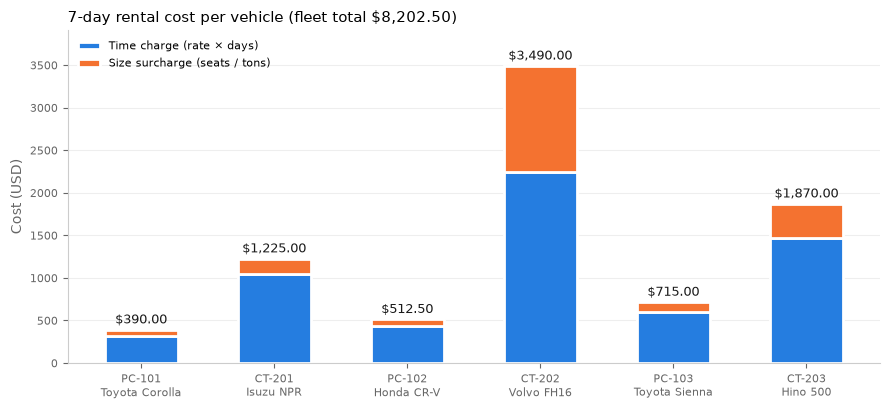

In [11]:
import matplotlib.pyplot as plt

DAYS = 7
labels = [f"{v.vehicle_id}\n{v.model}" for v in fleet]
time_part = [v.daily_rate * DAYS for v in fleet]
extra_part = [v.calculate_rental_cost(DAYS) - t for v, t in zip(fleet, time_part)]
totals = [t + e for t, e in zip(time_part, extra_part)]

fig, ax = plt.subplots(figsize=(9, 4.2))
bars1 = ax.bar(labels, time_part, width=0.55, color="#257de0", label="Time charge (rate × days)",
               edgecolor="white", linewidth=2)
ax.bar(labels, extra_part, width=0.55, bottom=time_part, color="#f47230",
       label="Size surcharge (seats / tons)", edgecolor="white", linewidth=2)
for x, total in enumerate(totals):
    ax.text(x, total + 40, f"${total:,.2f}", ha="center", va="bottom", fontsize=9, color="#191919")

ax.set_title(f"7-day rental cost per vehicle (fleet total ${sum(totals):,.2f})", loc="left", fontsize=11)
ax.set_ylabel("Cost (USD)", color="#666666")
ax.tick_params(colors="#666666", labelsize=8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")
ax.yaxis.grid(True, color="#eeeeee")
ax.set_axisbelow(True)
ax.set_ylim(0, max(totals) * 1.12)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Edge cases

In [12]:
for bad_days in (0, -2, 2.5):
    try:
        car.calculate_rental_cost(bad_days)
    except ValueError as err:
        print("Rejected:", err)

for bad_build in (lambda: PassengerCar("PC-0", "No Seats", 40, 0),
                  lambda: CargoTruck("CT-0", "No Bed", 90, 0)):
    try:
        bad_build()
    except ValueError as err:
        print("Rejected:", err)

print("Empty fleet total:", generate_fleet_manifest([], 5))

Rejected: Rental days must be a positive whole number, got 0.
Rejected: Rental days must be a positive whole number, got -2.
Rejected: Rental days must be a positive whole number, got 2.5.
Rejected: A passenger car needs at least one seat.
Rejected: Cargo capacity must be greater than 0 tons.
LOGITRANS LOGISTICS - FLEET RENTAL MANIFEST (5 day rental)
------------------------------------------------------------------------------
Vehicles dispatched: 0                                           $      0.00
Empty fleet total: 0.0


### Bonus: proving the design is open for extension
To test whether my manifest is really polymorphic, I added a **third** vehicle type that the function has never seen.
`ElectricVan` is a hypothetical example (charging fee of $0.20 per kWh of battery) and is *not* part of the required
fleet. `generate_fleet_manifest()` is **not edited at all**, yet it bills the van correctly.

In [13]:
class ElectricVan(Vehicle):
    CHARGE_FEE = 0.20

    def __init__(self, vehicle_id, model, daily_rate, battery_kwh):
        super().__init__(vehicle_id, model, daily_rate)
        self.battery_kwh = float(battery_kwh)

    def calculate_rental_cost(self, days):
        self._check_days(days)
        return (self.daily_rate * days) + (self.CHARGE_FEE * self.battery_kwh)

    def __str__(self):
        return (f"[Van]   {self.vehicle_id:<7} {self.model:<20} "
                f"${self.daily_rate:>7.2f}/day  {self.battery_kwh:.0f} kWh")


mixed = [PassengerCar("PC-101", "Toyota Corolla", 45.00, 5),
         ElectricVan("EV-301", "Ford E-Transit", 95.00, 89),
         CargoTruck("CT-201", "Isuzu NPR", 150.00, 3.5)]
bonus_total = generate_fleet_manifest(mixed, 2)

LOGITRANS LOGISTICS - FLEET RENTAL MANIFEST (2 day rental)
[Car]   PC-101  Toyota Corolla       $  45.00/day  5 seats       $    165.00
[Van]   EV-301  Ford E-Transit       $  95.00/day  89 kWh        $    207.80
[Truck] CT-201  Isuzu NPR            $ 150.00/day  3.5 tons      $    475.00
------------------------------------------------------------------------------
Vehicles dispatched: 3                                           $    847.80


## Summary
- `Vehicle` cannot be instantiated, which shows **abstraction**.
- `__daily_rate` is hidden by name mangling and every change goes through the validating setter, which shows **encapsulation**.
- `PassengerCar` and `CargoTruck` reuse the base constructor through `super()`, which shows **inheritance**.
- Each vehicle bills and prints itself, `sorted()` works through `__lt__`, and `generate_fleet_manifest()` handles the mixed
  list without type checks, which shows **polymorphism**. The bonus `ElectricVan` proves a new vehicle type needs no change to the manifest.
- The program's results match my hand calculations: a 7-day rental of the six-vehicle fleet costs **$8,202.50**.